<a href="https://colab.research.google.com/github/stevenalu/Formative-2-Multimodal/blob/main/notebooks/Group_11_product_recommendation_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Formative 2: Multimodal Data Preprocessing

**Group 11**

**Course:** Machine Learning Pipeline

**Programme:** BSE (Machine Learning)

**Notebook:** Data Merge and Product Recommendation Model

## Introduction

This notebook covers the part where we develop a product recommendation model, following the pre-steps of data merging given two csv files. At the end, we are building a system where a user is first checked by a facial recognition model, then by a voiceprint verification model, and only after both checks pass does the system recommend a product to that user.

My part is the last block in that flow. I take the two customer datasets we were given, merge them into one clean dataset, and train a model that predicts which product category a customer is likely to buy based on their social media behaviour.

The works in order:

Simply, I will follow the machine learning pipeline, starting from data loading, EDA, model training and model saving.

1. Load both datasets and inspect them.
2. Check missing values, duplicates and data types.
3. Run the exploratory analysis with plots.
4. Merge the two sources and validate the result.
5. Engineer the features and split the data.
6. Train Random Forest, Logistic Regression and XGBoost, then tune them.
7. Compare the models and save the best one with joblib so the CLI app can load it.

### Libraries

All the libraries used in this notebook are imported here.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, log_loss, classification_report, confusion_matrix
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 30)

## 1. Loading the Data

We were given two CSV files. One has the transaction history and the other has the social media
profiles. Load both and look at the size of each.

In [2]:
transactions = pd.read_csv('/content/customer_transactions - customer_transactions.csv')
social = pd.read_csv('/content/customer_social_profiles - customer_social_profiles.csv')

print('transactions:', transactions.shape)
print('social:', social.shape)

transactions: (150, 6)
social: (155, 5)


### Transactions dataset

In [3]:
transactions.info()
transactions.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id_legacy  150 non-null    int64  
 1   transaction_id      150 non-null    int64  
 2   purchase_amount     150 non-null    int64  
 3   purchase_date       150 non-null    object 
 4   product_category    150 non-null    object 
 5   customer_rating     140 non-null    float64
dtypes: float64(1), int64(3), object(2)
memory usage: 7.2+ KB


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


In [4]:
transactions.describe()

,customer_id_legacy,transaction_id,purchase_amount,customer_rating
count,150.000000,150.000000,150.000000,140.00000
mean,148.760000,1075.500000,280.780000,2.98500
std,30.046425,43.445368,121.329595,1.20699
min,100.000000,1001.000000,51.000000,1.00000
25%,121.250000,1038.250000,179.000000,1.95000
50%,150.500000,1075.500000,274.000000,3.00000
75%,174.750000,1112.750000,388.500000,4.00000
max,199.000000,1150.000000,495.000000,5.00000


### Social profiles dataset

In [5]:
social.info()
social.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id_new          155 non-null    object 
 1   social_media_platform    155 non-null    object 
 2   engagement_score         155 non-null    int64  
 3   purchase_interest_score  155 non-null    float64
 4   review_sentiment         155 non-null    object 
dtypes: float64(1), int64(1), object(3)
memory usage: 6.2+ KB


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


In [6]:
social.describe()

,engagement_score,purchase_interest_score
count,155.000000,155.000000
mean,75.606452,3.152903
std,14.568021,1.142867
min,50.000000,1.000000
25%,63.500000,2.350000
50%,77.000000,3.200000
75%,87.500000,4.100000
max,99.000000,5.000000


**What we see so far**

The transactions table has 150 rows and 6 columns. Four of them are useful for modelling
(`purchase_amount`, `product_category`, `customer_rating`, `purchase_date`) and two are identifiers.
`customer_rating` only has 140 non null values, so 10 values are missing there.

The social table has 155 rows and 5 columns. Nothing is missing. The customer id here is written as
text (`A178`) while the transactions table uses a plain number (`178`), so the two keys do not match
yet.

`purchase_date` is loaded as object instead of datetime, so that type needs to be fixed.

## 2. Missing Values, Duplicates and Types

Before touching anything we check the three usual problems: nulls, duplicate rows, and wrong data
types.

In [7]:
print('Missing values in transactions:')
print(transactions.isnull().sum())

print('\nMissing values in social:')
print(social.isnull().sum())

Missing values in transactions:
customer_id_legacy     0
transaction_id         0
purchase_amount        0
purchase_date          0
product_category       0
customer_rating       10
dtype: int64

Missing values in social:
customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_sentiment           0
dtype: int64


In [8]:
print('Duplicate rows in transactions:', transactions.duplicated().sum())
print('Duplicate rows in social:', social.duplicated().sum())

print('\nUnique customers in transactions:', transactions['customer_id_legacy'].nunique())
print('Unique customers in social:', social['customer_id_new'].nunique())

Duplicate rows in transactions: 0
Duplicate rows in social: 5

Unique customers in transactions: 75
Unique customers in social: 84


**Findings**

Only `customer_rating` has missing values, 10 out of 150, which is about 6.7 percent. That is small
enough to fill rather than drop, because dropping would throw away 10 transactions we need.

The transactions table has no duplicate rows. The social table has 5 exact duplicate rows. These are
full copies of other rows, so they add no information and they would give some customers more weight
than others during the merge. They have to go.

The social table also has more rows (155) than unique customers (84), which means one customer can
appear several times, once per platform. This matters for how we join.

## 3. Cleaning

Three things are fixed here: the missing ratings, the duplicate social rows, and the date column.
We also pull the number out of the social customer id so both tables share the same key.

In [9]:
transactions_clean = transactions.copy()
social_clean = social.copy()

# fill the 10 missing ratings with the median, the column is not symmetric so mean is less safe
median_rating = transactions_clean['customer_rating'].median()
transactions_clean['customer_rating'] = transactions_clean['customer_rating'].fillna(median_rating)

# purchase_date should be a date, not text
transactions_clean['purchase_date'] = pd.to_datetime(transactions_clean['purchase_date'])

# remove the 5 exact duplicate rows from the social table
social_clean = social_clean.drop_duplicates()

# A178 becomes 178 so it matches customer_id_legacy
social_clean['customer_id'] = social_clean['customer_id_new'].str.extract(r'(\d+)').astype(int)
transactions_clean = transactions_clean.rename(columns={'customer_id_legacy': 'customer_id'})

print('median rating used:', median_rating)
print('transactions after cleaning:', transactions_clean.shape)
print('social after cleaning:', social_clean.shape)
print('remaining nulls:', transactions_clean.isnull().sum().sum() + social_clean.isnull().sum().sum())

median rating used: 3.0
transactions after cleaning: (150, 6)
social after cleaning: (150, 6)
remaining nulls: 0


In [10]:
transactions_clean.dtypes

,0
customer_id,int64
transaction_id,int64
purchase_amount,int64
purchase_date,datetime64[ns]
product_category,object
customer_rating,float64


**Result of cleaning**

The median rating is 3.0 and that value was used for the 10 gaps. The social table dropped from 155
to 150 rows after removing the duplicates. No nulls are left in either table and `purchase_date` is
now a proper datetime.

## 4. Exploratory Data Analysis

Now we look at the data visually. The goal is to understand the spread of the numeric columns, check
for outliers, see how balanced the target is, and look for any relationship between the social
behaviour and what people buy.

### 4.1 Distribution of the numeric columns

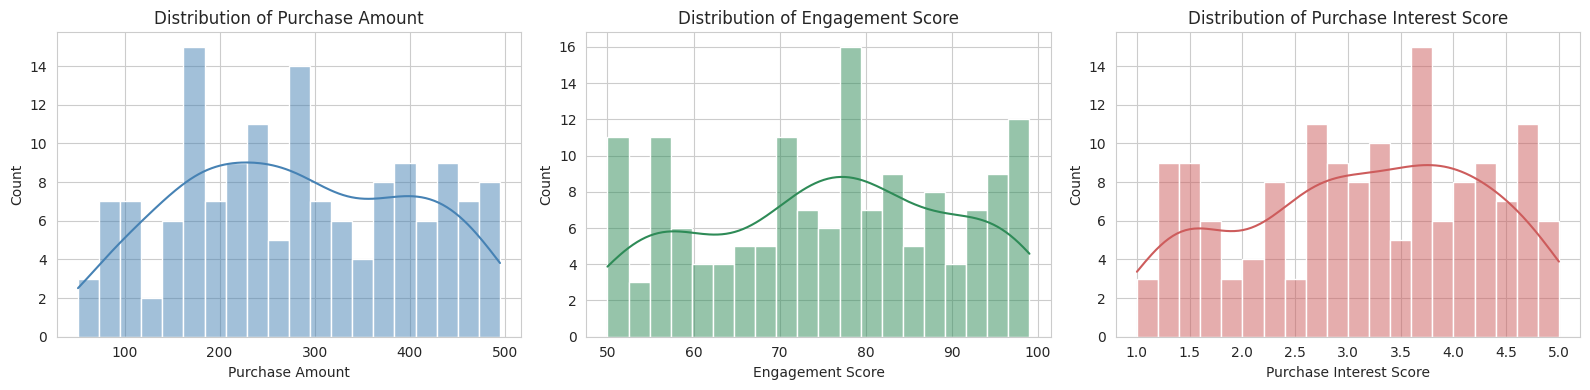

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(transactions_clean['purchase_amount'], bins=20, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Distribution of Purchase Amount')
axes[0].set_xlabel('Purchase Amount')

sns.histplot(social_clean['engagement_score'], bins=20, kde=True, color='seagreen', ax=axes[1])
axes[1].set_title('Distribution of Engagement Score')
axes[1].set_xlabel('Engagement Score')

sns.histplot(social_clean['purchase_interest_score'], bins=20, kde=True, color='indianred', ax=axes[2])
axes[2].set_title('Distribution of Purchase Interest Score')
axes[2].set_xlabel('Purchase Interest Score')

plt.tight_layout()
plt.show()

**Reading the distributions**

Purchase amounts run from about 50 to 500 and the shape is close to flat, with no long tail on either
side. There is no single price point that dominates.

Engagement score sits between 50 and 99 and is also spread out rather than peaked. Purchase interest
runs the full 1 to 5 range.

None of the three columns is strongly skewed, so we do not need a log transform or any similar fix
before modelling.

### 4.2 Outlier check

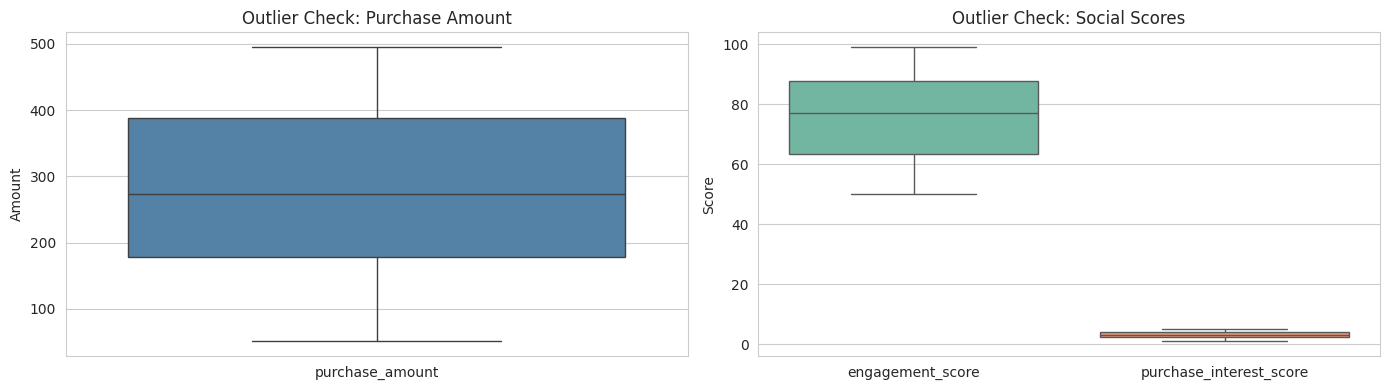

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(data=transactions_clean[['purchase_amount']], color='steelblue', ax=axes[0])
axes[0].set_title('Outlier Check: Purchase Amount')
axes[0].set_ylabel('Amount')

sns.boxplot(data=social_clean[['engagement_score', 'purchase_interest_score']], palette='Set2', ax=axes[1])
axes[1].set_title('Outlier Check: Social Scores')
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.show()

**Reading the boxplots**

No points fall outside the whiskers in any of the three columns. The purchase amount median is around
274 and the box covers roughly 179 to 388. Engagement score has a median near 77 and purchase
interest near 3.2.

Since there are no outliers, we keep every row. No clipping or winsorising is needed.

### 4.3 Balance of the target variable

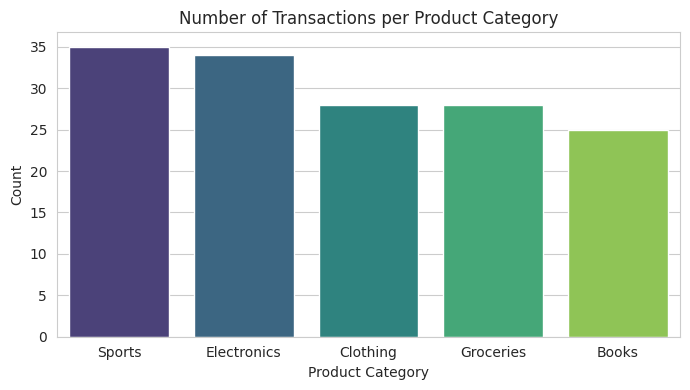

,count
product_category,
Sports,35
Electronics,34
Clothing,28
Groceries,28
Books,25


In [13]:
plt.figure(figsize=(7, 4))
order = transactions_clean['product_category'].value_counts().index
sns.countplot(data=transactions_clean, x='product_category', order=order, palette='viridis')
plt.title('Number of Transactions per Product Category')
plt.xlabel('Product Category')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

transactions_clean['product_category'].value_counts()

**Reading the target**

The five categories are fairly even. Sports is the largest with 35 transactions and Books the
smallest with 25. The ratio between the biggest and smallest class is only 1.4, so this is not an
imbalanced problem and we do not need SMOTE or class weights.

Because it is close to even, a model that guesses randomly would score around 20 percent accuracy.
That is the number to beat.

## 5. Merging the Two Datasets

The two tables do not have the same shape of key. One customer has one row per social platform they
use, but many transaction rows. A plain inner join would therefore multiply rows: a customer with 3
social rows and 4 transactions would produce 12 rows, and the same transaction would appear 3 times.

That is a problem because the same transaction could then land in both the training and the test set,
which inflates the scores. We checked it and a plain join turns 150 transactions into 213 rows.

To avoid that we first collapse the social table to one row per customer, then join. The social
columns are summarised like this:

* `engagement_score` and `purchase_interest_score`: average across the customer's platforms
* `platform_count`: how many different platforms the customer is active on
* `main_platform`: the platform the customer appears on most
* `main_sentiment`: the sentiment that appears most in the customer's reviews

An inner join is used because the model needs both the social features and the product category, so a
row is only useful if both sides exist.

In [14]:
# show the problem first
plain_join = transactions_clean.merge(social_clean, on='customer_id', how='inner')
print('rows after a plain join:', plain_join.shape[0], '(transactions were', transactions_clean.shape[0], ')')
print('social rows per customer:')
print(social_clean.groupby('customer_id').size().value_counts().sort_index())

rows after a plain join: 213 (transactions were 150 )
social rows per customer:
1    43
2    23
3    13
4     4
6     1
Name: count, dtype: int64


In [15]:
profile = social_clean.groupby('customer_id').agg(
    engagement_score=('engagement_score', 'mean'),
    purchase_interest_score=('purchase_interest_score', 'mean'),
    platform_count=('social_media_platform', 'nunique')
).reset_index()

profile['main_platform'] = social_clean.groupby('customer_id')['social_media_platform'].agg(lambda x: x.mode()[0]).values
profile['main_sentiment'] = social_clean.groupby('customer_id')['review_sentiment'].agg(lambda x: x.mode()[0]).values

profile['engagement_score'] = profile['engagement_score'].round(2)
profile['purchase_interest_score'] = profile['purchase_interest_score'].round(2)

print('one row per customer:', profile.shape)
profile.head()

one row per customer: (84, 6)


,customer_id,engagement_score,purchase_interest_score,platform_count,main_platform,main_sentiment
0,100,77.00,4.40,2,Instagram,Negative
1,101,68.00,1.00,1,Twitter,Neutral
2,102,51.00,4.80,1,LinkedIn,Neutral
3,103,64.33,2.87,2,Instagram,Positive
4,104,83.00,2.93,2,Twitter,Negative


In [16]:
merged = transactions_clean.merge(profile, on='customer_id', how='inner')
print('merged dataset:', merged.shape)
merged.head()

merged dataset: (117, 11)


,customer_id,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,engagement_score,purchase_interest_score,platform_count,main_platform,main_sentiment
0,151,1001,408,2024-01-01,Sports,2.3,71.67,2.17,2,Twitter,Neutral
1,192,1002,332,2024-01-02,Electronics,4.2,60.00,4.30,1,Instagram,Positive
2,114,1003,442,2024-01-03,Electronics,2.1,87.00,4.80,1,Facebook,Negative
3,160,1005,64,2024-01-05,Clothing,1.3,72.67,2.50,3,Instagram,Neutral
4,120,1006,395,2024-01-06,Groceries,1.1,77.00,2.67,2,Instagram,Positive


### 5.1 Post merge validation

After a merge we always check that nothing was broken. Four checks are run below.

In [17]:
print('1. Rows:', merged.shape[0], 'out of', transactions_clean.shape[0], 'transactions')
print('2. Duplicated transaction ids:', merged['transaction_id'].duplicated().sum())
print('3. Nulls after merge:', merged.isnull().sum().sum())
print('4. Customers in merged data:', merged['customer_id'].nunique())

only_in_transactions = set(transactions_clean['customer_id']) - set(profile['customer_id'])
print('   Customers with transactions but no social profile:', len(only_in_transactions))
print('\nTarget balance after merge:')
print(merged['product_category'].value_counts())

1. Rows: 117 out of 150 transactions
2. Duplicated transaction ids: 0
3. Nulls after merge: 0
4. Customers in merged data: 61
   Customers with transactions but no social profile: 14

Target balance after merge:
product_category
Sports         28
Electronics    27
Clothing       22
Groceries      20
Books          20
Name: count, dtype: int64


**Merge validation result**

The merge produced 117 rows from 150 transactions. No transaction id is repeated, which confirms the
one to many problem is gone and every row is still a single real transaction.

The 33 rows that were dropped belong to 14 customers who have transactions but no social profile. We
cannot use those rows because the model is built on social features, so dropping them is correct
rather than filling them with made up values.

No nulls were introduced and the five categories are still close to even after the merge, so the
smaller dataset did not break the balance.

### 5.2 Correlation between the numeric features

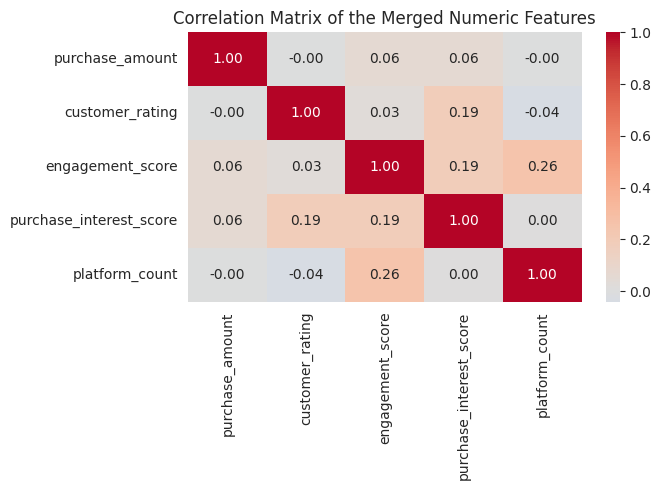

In [18]:
plt.figure(figsize=(7, 5))
numeric_cols = ['purchase_amount', 'customer_rating', 'engagement_score',
                'purchase_interest_score', 'platform_count']
sns.heatmap(merged[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix of the Merged Numeric Features')
plt.tight_layout()
plt.show()

**Reading the correlation matrix**

Every pair sits close to zero. The strongest value is 0.26, between engagement score and platform
count, which just says that customers on more platforms tend to have slightly higher engagement.
Everything else is below 0.1.

Two things follow from this. First, there is no multicollinearity, so we can keep all the numeric
features. Second, no single feature has a straight line relationship with the others, which means a
linear model will probably struggle and tree based models are the better choice here.

### 5.3 Social behaviour against product category

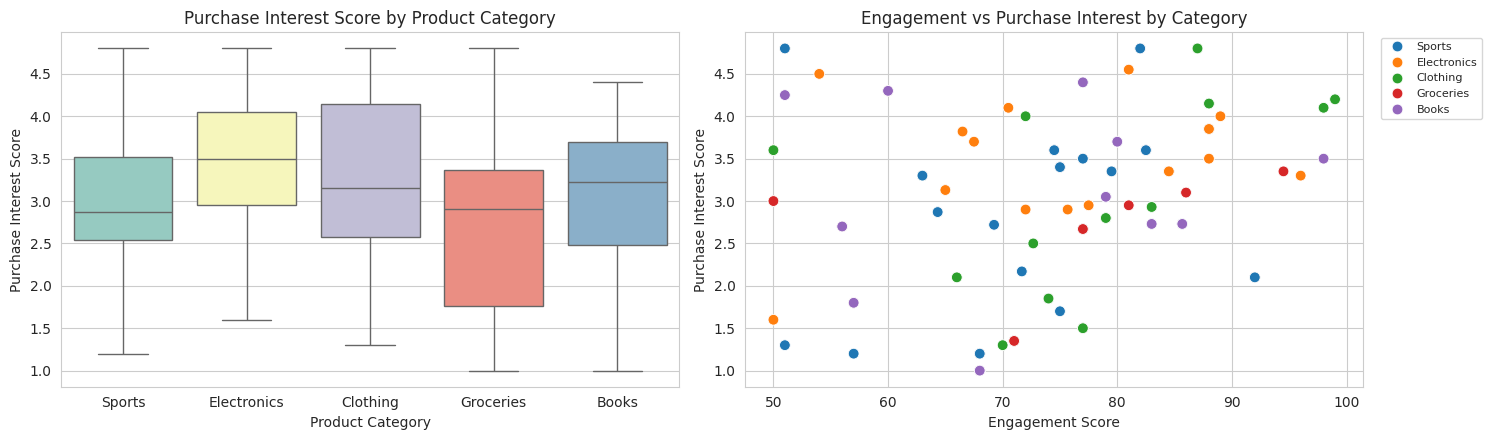

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

sns.boxplot(data=merged, x='product_category', y='purchase_interest_score', palette='Set3', ax=axes[0])
axes[0].set_title('Purchase Interest Score by Product Category')
axes[0].set_xlabel('Product Category')
axes[0].set_ylabel('Purchase Interest Score')

sns.scatterplot(data=merged, x='engagement_score', y='purchase_interest_score',
                hue='product_category', palette='tab10', s=60, ax=axes[1])
axes[1].set_title('Engagement vs Purchase Interest by Category')
axes[1].set_xlabel('Engagement Score')
axes[1].set_ylabel('Purchase Interest Score')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

**Reading the relationship with the target**

The boxplots show the categories sitting at slightly different levels of purchase interest. Sports
is lowest with a median of 2.87 and Electronics highest at 3.50, but the boxes overlap almost
completely.

The scatter plot shows the same thing. The colours are mixed across the whole space instead of
forming separate groups.

This tells us early that the signal in this dataset is weak. The model will find something, but we
should not expect high accuracy from 117 rows with features that overlap this much.

## 6. Feature Engineering and Data Split

The features come from the social side of the merged data, plus one extra feature we create.

`engagement_per_platform` is the engagement score divided by the number of platforms. It separates a
customer who is very active on one platform from a customer who spreads the same activity across
four.

`purchase_amount` and `customer_rating` are left out on purpose. Both of them describe a transaction
that has already happened, but the system has to recommend a product before the customer buys
anything, so using them would be leakage. The categorical columns are one hot encoded.

In [21]:
merged['engagement_per_platform'] = (merged['engagement_score'] / merged['platform_count']).round(2)

merged.to_csv('/content/merged_customer_data.csv', index=False)
print('saved content/merged_customer_data.csv', merged.shape)
merged.head()

saved content/merged_customer_data.csv (117, 12)


,customer_id,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,engagement_score,purchase_interest_score,platform_count,main_platform,main_sentiment,engagement_per_platform
0,151,1001,408,2024-01-01,Sports,2.3,71.67,2.17,2,Twitter,Neutral,35.84
1,192,1002,332,2024-01-02,Electronics,4.2,60.00,4.30,1,Instagram,Positive,60.00
2,114,1003,442,2024-01-03,Electronics,2.1,87.00,4.80,1,Facebook,Negative,87.00
3,160,1005,64,2024-01-05,Clothing,1.3,72.67,2.50,3,Instagram,Neutral,24.22
4,120,1006,395,2024-01-06,Groceries,1.1,77.00,2.67,2,Instagram,Positive,38.50


In [22]:
features = ['engagement_score', 'purchase_interest_score', 'platform_count',
            'engagement_per_platform', 'main_platform', 'main_sentiment']

X = pd.get_dummies(merged[features], columns=['main_platform', 'main_sentiment'])
y = merged['product_category']

print('feature matrix:', X.shape)
print(X.columns.tolist())
X.head()

feature matrix: (117, 12)
['engagement_score', 'purchase_interest_score', 'platform_count', 'engagement_per_platform', 'main_platform_Facebook', 'main_platform_Instagram', 'main_platform_LinkedIn', 'main_platform_TikTok', 'main_platform_Twitter', 'main_sentiment_Negative', 'main_sentiment_Neutral', 'main_sentiment_Positive']


,engagement_score,purchase_interest_score,platform_count,engagement_per_platform,main_platform_Facebook,main_platform_Instagram,main_platform_LinkedIn,main_platform_TikTok,main_platform_Twitter,main_sentiment_Negative,main_sentiment_Neutral,main_sentiment_Positive
0,71.67,2.17,2,35.84,False,False,False,False,True,False,True,False
1,60.00,4.30,1,60.00,False,True,False,False,False,False,False,True
2,87.00,4.80,1,87.00,True,False,False,False,False,True,False,False
3,72.67,2.50,3,24.22,False,True,False,False,False,False,True,False
4,77.00,2.67,2,38.50,False,True,False,False,False,False,False,True


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

label_encoder = LabelEncoder()
y_train_enc = label_encoder.fit_transform(y_train)
y_test_enc = label_encoder.transform(y_test)

print('train:', X_train.shape)
print('test:', X_test.shape)
print('\nclass balance in train:')
print(y_train.value_counts())

train: (93, 12)
test: (24, 12)

class balance in train:
product_category
Sports         22
Electronics    21
Clothing       18
Books          16
Groceries      16
Name: count, dtype: int64


**About the split**

The split is 80/20 and stratified so both sides keep the same category proportions. That leaves 93
rows for training and 24 for testing.

24 test rows is small, so a single test score can swing a lot just from one or two predictions. To
avoid reading too much into that, every model below is also scored with 5 fold cross validation on
the training set, and the cross validation score is what we use to choose the final model.

## 7. Model Training

Three algorithms are tried: Random Forest, Logistic Regression and XGBoost. Each one is scored with
accuracy, weighted F1 and log loss, plus the cross validation accuracy described above.

A small helper is used so all the models are scored the same way.

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

def evaluate(name, model, encoded=False):
    y_true = y_test_enc if encoded else y_test
    y_fit = y_train_enc if encoded else y_train
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)
    labels = sorted(np.unique(y_fit))

    accuracy = accuracy_score(y_true, predictions)
    f1 = f1_score(y_true, predictions, average='weighted', zero_division=0)
    loss = log_loss(y_true, probabilities, labels=labels)
    cv_accuracy = cross_val_score(model, X_train, y_fit, cv=cv, scoring='accuracy').mean()

    results.append({'Model': name, 'CV Accuracy': round(cv_accuracy, 3),
                    'Test Accuracy': round(accuracy, 3), 'F1 Score': round(f1, 3),
                    'Log Loss': round(loss, 3)})
    print(f'{name}')
    print(f'  CV accuracy  : {cv_accuracy:.3f}')
    print(f'  Test accuracy: {accuracy:.3f}')
    print(f'  F1 score     : {f1:.3f}')
    print(f'  Log loss     : {loss:.3f}')

### 7.1 Experiment 1: Random Forest baseline

In [25]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
evaluate('Random Forest (baseline)', rf)

Random Forest (baseline)
  CV accuracy  : 0.236
  Test accuracy: 0.250
  F1 score     : 0.237
  Log loss     : 3.550


Accuracy is 0.250, which is above the 0.20 we would get from random guessing but not by much. The log
loss of 3.550 is the real problem. A model that knows nothing would score about 1.61 on five classes,
so 3.550 means the forest is giving very confident probabilities to the wrong class. That is a sign
of overfitting on 93 training rows.

### 7.2 Experiment 2: Logistic Regression

In [26]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))
logreg.fit(X_train, y_train)
evaluate('Logistic Regression', logreg)

Logistic Regression
  CV accuracy  : 0.257
  Test accuracy: 0.125
  F1 score     : 0.111
  Log loss     : 1.990


Logistic regression has the worst accuracy of the three at 0.125, which is below random guessing. Its
log loss of 1.990 is much better than the forest though, because it is not overconfident.

This matches what the correlation matrix showed. The relationship between the social features and the
product category is not linear, so drawing straight boundaries between the five classes does not
work. We drop this model from the rest of the work.

### 7.3 Experiment 3: XGBoost baseline

In [27]:
xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=5,
                    random_state=42, eval_metric='mlogloss')
xgb.fit(X_train, y_train_enc)
evaluate('XGBoost (baseline)', xgb, encoded=True)

XGBoost (baseline)
  CV accuracy  : 0.247
  Test accuracy: 0.292
  F1 score     : 0.281
  Log loss     : 3.114


XGBoost gives the best test accuracy so far at 0.292 and the best F1 at 0.281. The log loss is still
high at 3.114 for the same reason as the forest: with `max_depth=5` and 200 trees it is building a
model far too complex for 93 rows.

Both tree models need regularisation, so the next step is tuning.

### 7.4 Experiment 4: Tuned Random Forest

We use GridSearchCV to look for shallower trees and larger leaves, which should stop the forest from
memorising the training rows.

In [28]:
rf_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 6, None],
    'min_samples_leaf': [1, 2, 3],
    'max_features': ['sqrt', 'log2']
}

rf_search = GridSearchCV(RandomForestClassifier(random_state=42), rf_grid,
                         cv=cv, scoring='f1_weighted', n_jobs=-1)
rf_search.fit(X_train, y_train)

print('best parameters:', rf_search.best_params_)
print('best CV F1:', round(rf_search.best_score_, 3))

tuned_rf = rf_search.best_estimator_
evaluate('Random Forest (tuned)', tuned_rf)

best parameters: {'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 200}
best CV F1: 0.274
Random Forest (tuned)
  CV accuracy  : 0.289
  Test accuracy: 0.125
  F1 score     : 0.143
  Log loss     : 1.711


The search picked `max_depth=3` and `min_samples_leaf=2`, which is a much simpler forest than the
baseline.

The effect on log loss is large: it drops from 3.550 to 1.711, close to the 1.61 reference. The
probabilities are now honest instead of overconfident. Cross validation accuracy also improves from
0.236 to 0.289.

Test accuracy drops to 0.125, but on 24 rows that is three correct predictions instead of six, so it
is within the noise of such a small test set. The cross validation score, which averages over the
whole training set, is the more reliable signal and it went up.

### 7.5 Experiment 5: Tuned XGBoost

The same approach is applied to XGBoost. Here we also tune `reg_lambda`, which penalises large leaf
weights, and `subsample`.

In [29]:
xgb_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [2, 3, 4],
    'subsample': [0.8, 1.0],
    'reg_lambda': [1, 3, 5]
}

xgb_search = GridSearchCV(XGBClassifier(random_state=42, eval_metric='mlogloss'), xgb_grid,
                          cv=cv, scoring='f1_weighted', n_jobs=-1)
xgb_search.fit(X_train, y_train_enc)

print('best parameters:', xgb_search.best_params_)
print('best CV F1:', round(xgb_search.best_score_, 3))

tuned_xgb = xgb_search.best_estimator_
evaluate('XGBoost (tuned)', tuned_xgb, encoded=True)

best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'reg_lambda': 5, 'subsample': 1.0}
best CV F1: 0.27
XGBoost (tuned)
  CV accuracy  : 0.290
  Test accuracy: 0.250
  F1 score     : 0.226
  Log loss     : 2.144


The tuned XGBoost keeps the 0.250 accuracy of the baseline forest, raises cross validation accuracy
to 0.290, the highest of all five runs, and brings log loss down from 3.114 to 2.144.

So compared to its own baseline it lost nothing in accuracy and became far better calibrated.

## 8. Model Comparison and Selection

In [30]:
comparison = pd.DataFrame(results)
comparison

,Model,CV Accuracy,Test Accuracy,F1 Score,Log Loss
0,Random Forest (baseline),0.236,0.250,0.237,3.550
1,Logistic Regression,0.257,0.125,0.111,1.990
2,XGBoost (baseline),0.247,0.292,0.281,3.114
3,Random Forest (tuned),0.289,0.125,0.143,1.711
4,XGBoost (tuned),0.290,0.250,0.226,2.144


**Choosing the final model**

Looking at the table, the two tuned models are clearly better than their baselines on cross
validation accuracy and on log loss, which is what we expected after seeing how badly the baselines
were overfitting.

Between them, the tuned XGBoost is chosen:

* It has the highest cross validation accuracy at 0.290, and that is the metric we trust most with
  only 24 test rows.
* It has a test accuracy of 0.250 and an F1 of 0.226, both higher than the tuned forest.
* Its log loss of 2.144 is a big improvement on its own baseline, so the probabilities it returns are
  usable as a confidence score in the CLI app.

The tuned Random Forest does have a lower log loss, but its test accuracy of 0.125 is the weakest of
the tree models, so XGBoost is the better overall balance.

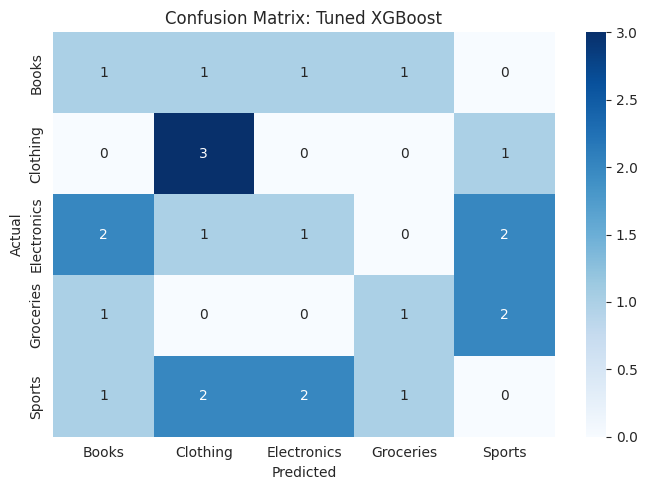

              precision    recall  f1-score   support

       Books       0.20      0.25      0.22         4
    Clothing       0.43      0.75      0.55         4
 Electronics       0.25      0.17      0.20         6
   Groceries       0.33      0.25      0.29         4
      Sports       0.00      0.00      0.00         6

    accuracy                           0.25        24
   macro avg       0.24      0.28      0.25        24
weighted avg       0.22      0.25      0.23        24



In [31]:
plt.figure(figsize=(7, 5))
final_predictions = label_encoder.inverse_transform(tuned_xgb.predict(X_test))
matrix = confusion_matrix(y_test, final_predictions, labels=label_encoder.classes_)
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix: Tuned XGBoost')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

print(classification_report(y_test, final_predictions, zero_division=0))

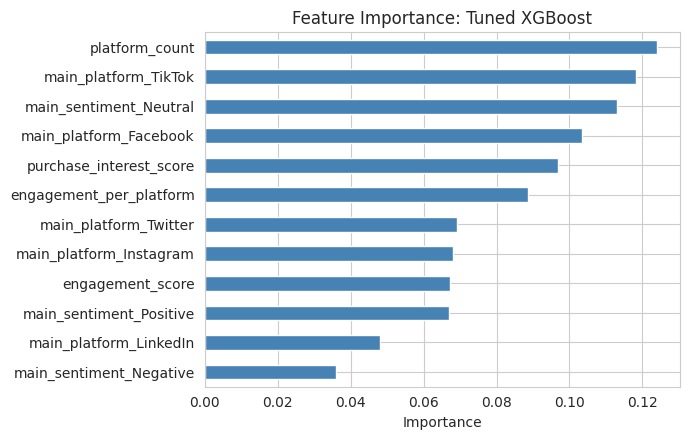

In [32]:
plt.figure(figsize=(7, 4.5))
importance = pd.Series(tuned_xgb.feature_importances_, index=X.columns).sort_values()
importance.plot(kind='barh', color='steelblue')
plt.title('Feature Importance: Tuned XGBoost')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

**What the model learned**

The confusion matrix shows the predictions spread across all five categories rather than collapsing
into one or two, which is what we want from a recommender. Clothing is the category the model handles
best, getting 3 of 4 right. Sports is the weakest: the model predicts it 5 times and is wrong every
time, so its recall is 0.

The feature importance chart is flat. The top feature, `platform_count`, only scores 0.124 and the
lowest is 0.036, so nothing stands out. In a model that had found a real pattern we would expect one
or two features well ahead of the rest. A flat chart like this says the model is pulling a little bit
of signal from everywhere, and no single behaviour tells us what a customer will buy.

## 9. Saving the Model

The CLI application built by the rest of the group needs more than the model object. It needs the
label encoder to turn a prediction back into a category name, and the exact feature order used during
training, otherwise the columns will not line up. All three are saved together in one joblib file.

In [33]:
import os
os.makedirs('models', exist_ok=True)

model_bundle = {
    'model': tuned_xgb,
    'label_encoder': label_encoder,
    'features': X.columns.tolist(),
    'categories': label_encoder.classes_.tolist()
}

joblib.dump(model_bundle, 'models/product_recommendation_model.joblib')
print('saved models/product_recommendation_model.joblib')

saved models/product_recommendation_model.joblib


### 9.1 Loading the model back

This is a quick check that the saved file works on its own, and it also shows the group how to call
it from the CLI app. We take one customer from the merged dataset and ask the model what to
recommend.

In [34]:
bundle = joblib.load('models/product_recommendation_model.joblib')

def recommend_for_customer(customer_id, data=merged, bundle=bundle):
    row = data[data['customer_id'] == customer_id]
    if row.empty:
        return None

    row = row.iloc[[0]]
    encoded = pd.get_dummies(row[features], columns=['main_platform', 'main_sentiment'])
    encoded = encoded.reindex(columns=bundle['features'], fill_value=0)

    prediction = bundle['model'].predict(encoded)[0]
    confidence = bundle['model'].predict_proba(encoded)[0].max()
    category = bundle['label_encoder'].inverse_transform([prediction])[0]
    return category, round(float(confidence), 3)


for customer in [151, 187, 174, 160]:
    category, confidence = recommend_for_customer(customer)
    print(f'customer {customer} -> {category} (confidence {confidence})')

customer 151 -> Clothing (confidence 0.5)
customer 187 -> Sports (confidence 0.691)
customer 174 -> Sports (confidence 0.432)
customer 160 -> Sports (confidence 0.395)


The saved bundle loads and predicts correctly on its own, so the CLI app only needs to import joblib,
read this file and call the same three steps.

## 10. Conclusion

The two datasets were merged into one clean table of 117 transactions after handling 10 missing
ratings, 5 duplicate social rows and a key format that did not match. The merge was done on a
summarised social profile rather than the raw social table, which kept every transaction unique and
avoided the row duplication a plain join would have caused.

Five experiments were run. The baselines overfit badly, with log loss above 3 on a problem where 1.61
means knowing nothing. Tuning fixed that. The tuned XGBoost was selected as the final model with a
cross validation accuracy of 0.290, a test accuracy of 0.250, an F1 of 0.226 and a log loss of 2.144.

The honest limitation is the data. 117 rows across 5 categories is small, and the correlation matrix
and the scatter plot both showed from the start that the social features barely separate the classes.
Beating random guessing by about 9 points is roughly what this dataset supports. More rows per
customer, or purchase history features such as what the customer bought before, would be the way to
improve it.

The model, the label encoder and the feature order are saved in
`models/product_recommendation_model.joblib`, and the merged dataset is saved in
`dataset/merged_customer_data.csv`. Both are ready for the facial recognition and voiceprint
verification parts of the system to use.